<a href="https://colab.research.google.com/github/Anton-maxi/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Zboryk_Anton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практичні роботи 4–7. Мініпроєкт «Порівняння класичних моделей класифікації»

**Курс:** Розпізнавання образів та класичне машинне навчання  
**Студент:** Зборик Антон, ІН-42/2  
**Набір даних:** Heart Disease (UCI), файл `heart_disease.csv`

## Постановка задачі

**Об'єкт дослідження:** пацієнт, описаний клінічними характеристиками.

**Ознаки (13):** age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal.

**Цільова змінна:** `target`.

**Кількість класів:** 2 (бінарна класифікація з навчанням за розміченими даними).

**Позитивний клас:** 1 (ознаки серцевого захворювання наявні). Клас 0 означає, що ознак захворювання немає.

**Практична мета:** за характеристиками пацієнта визначити, чи належить він до класу з наявністю ознак серцевого захворювання, і порівняти класичні моделі класифікації за однаковою схемою стратифікованої крос-валідації.

**Основна метрика:** F1 для позитивного класу. Додаткові метрики: recall позитивного класу (важливо не пропустити хворого) та ROC AUC. Метрику обрано до початку експериментів і далі не змінюється.

**Застереження:** результати навчального мініпроєкту не є медичним діагнозом і не повинні використовуватися для клінічних рішень.

In [104]:
import os
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/3_course/Image_Recognition_and_Classical_Machine_Learning"
DATA_PATH = os.path.join(PROJECT_DIR, "data", "heart_disease.csv")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
REPORTS_DIR = os.path.join(PROJECT_DIR, "reports")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("Файл даних існує:", os.path.exists(DATA_PATH))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/3_course/Image_Recognition_and_Classical_Machine_Learning
Файл даних існує: True


In [105]:
df = pd.read_csv(DATA_PATH)

print("Розмір таблиці:", df.shape)
display(df.head())
print()
print(df.dtypes)

Розмір таблиці: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0



age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


In [106]:
print("Пропуски по стовпцях:")
print(df.isna().sum())
print("Усього пропусків:", df.isna().sum().sum())
print()
print("Розподіл класів (кількість):")
print(df["target"].value_counts())
print()
print("Розподіл класів (частка):")
print(df["target"].value_counts(normalize=True).round(4))
print()
print("Унікальні значення target:", sorted(df["target"].unique()))

Пропуски по стовпцях:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Усього пропусків: 6

Розподіл класів (кількість):
target
0    164
1    139
Name: count, dtype: int64

Розподіл класів (частка):
target
0    0.5413
1    0.4587
Name: proportion, dtype: float64

Унікальні значення target: [np.int64(0), np.int64(1)]


In [107]:
numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_column = "target"

print("Числові ознаки:", numeric_columns)
print("Категоріальні ознаки:", categorical_columns)
print("Цільова змінна:", target_column)

Числові ознаки: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Категоріальні ознаки: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Цільова змінна: target


## Первинний аудит даних

| Характеристика | Значення |
|---|---|
| Кількість об'єктів | 303 |
| Кількість вхідних ознак | 13 |
| Числові ознаки | age, trestbps, chol, thalach, oldpeak (5) |
| Категоріальні ознаки | sex, cp, fbs, restecg, exang, slope, ca, thal (8) |
| Кількість пропусків | 6 (ca: 4, thal: 2) |
| Кількість класів | 2 |
| Позитивний клас | 1 |

**Розподіл класів:** клас 0 – 164 об'єкти (54,13%), клас 1 – 139 об'єктів (45,87%). Класи майже збалансовані.

**Висновок:** дані придатні для побудови моделей. Значення `target` лише 0 і 1. Пропуски є тільки в ознаках `ca` і `thal`, тому їх заповнення виконуватиметься всередині Pipeline (мода, обчислена лише на навчальній частині). Частина категоріальних ознак (наприклад, `cp`) збережена числовими кодами, тому вони обробляються як категоріальні, а не як кількісні.

In [108]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df.drop(columns=[target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print()
print("Клас 0 і 1 у y_train:")
print(y_train.value_counts())
print("Клас 0 і 1 у y_test:")
print(y_test.value_counts())

X_train: (242, 13) | X_test: (61, 13)
y_train: (242,) | y_test: (61,)

Клас 0 і 1 у y_train:
target
0    131
1    111
Name: count, dtype: int64
Клас 0 і 1 у y_test:
target
0    33
1    28
Name: count, dtype: int64


In [109]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [110]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

In [111]:
numeric_pipeline_noscale = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_noscale = ColumnTransformer([
    ("num", numeric_pipeline_noscale, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

model_pipeline_noscale = Pipeline([
    ("preprocessor", preprocessor_noscale),
    ("classifier", LogisticRegression(max_iter=2000))
])

In [112]:
preprocessor.fit(X_train)
X_train_prepared = preprocessor.transform(X_train)

print("Форма X_train після препроцесингу:", X_train_prepared.shape)
print("Пропусків після препроцесингу:", np.isnan(X_train_prepared).sum())
print()
print(preprocessor.get_feature_names_out())

Форма X_train після препроцесингу: (242, 28)
Пропусків після препроцесингу: 0

['num__age' 'num__trestbps' 'num__chol' 'num__thalach' 'num__oldpeak'
 'cat__sex_0.0' 'cat__sex_1.0' 'cat__cp_1.0' 'cat__cp_2.0' 'cat__cp_3.0'
 'cat__cp_4.0' 'cat__fbs_0.0' 'cat__fbs_1.0' 'cat__restecg_0.0'
 'cat__restecg_1.0' 'cat__restecg_2.0' 'cat__exang_0.0' 'cat__exang_1.0'
 'cat__slope_1.0' 'cat__slope_2.0' 'cat__slope_3.0' 'cat__ca_0.0'
 'cat__ca_1.0' 'cat__ca_2.0' 'cat__ca_3.0' 'cat__thal_3.0' 'cat__thal_6.0'
 'cat__thal_7.0']


In [113]:
from sklearn.model_selection import cross_validate
import warnings
scoring={"F1":"f1",
         "ROC_AUC":"roc_auc",
         "RECALL":"recall"}

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = cross_validate(model_pipeline, X_train, y_train, cv=cv, scoring=scoring)
    model_pipeline.fit(X_train, y_train)
    clf = model_pipeline.named_steps["classifier"]

print("Результат cross_validate:", res)
print("CV F1, середнє:", res["test_F1"].mean())
print("CV F1, std:", res["test_F1"].std())
print("CV ROC AUC, середнє:", res["test_ROC_AUC"].mean())
print("CV ROC AUC, std:", res["test_ROC_AUC"].std())
print("CV Recall, середнє:", res["test_RECALL"].mean())

print("Ітерацій оптимізатора після fit на train:", clf.n_iter_[0])

print("Кількість попереджень:", len(caught))

Результат cross_validate: {'fit_time': array([0.03572226, 0.03378892, 0.0306828 , 0.03214073, 0.02891994]), 'score_time': array([0.03960466, 0.03777218, 0.03360057, 0.04133439, 0.03322339]), 'test_F1': array([0.82608696, 0.82051282, 0.82051282, 0.81818182, 0.8372093 ]), 'test_ROC_AUC': array([0.9180602 , 0.90909091, 0.88986014, 0.91433566, 0.88111888]), 'test_RECALL': array([0.82608696, 0.72727273, 0.72727273, 0.81818182, 0.81818182])}
CV F1, середнє: 0.8245007436109558
CV F1, std: 0.006866722884370779
CV ROC AUC, середнє: 0.9024931590148981
CV ROC AUC, std: 0.01443995119614911
CV Recall, середнє: 0.783399209486166
Ітерацій оптимізатора після fit на train: 18
Кількість попереджень: 6


In [114]:
print("Попередження, які зловили (caught):")
for elm in caught:
    print("Тип:", elm.category.__name__)
    print("Текст:", str(elm.message)[:120])

Попередження, які зловили (caught):
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.
Тип: DeprecationWarning
Текст: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.


In [115]:
import pandas as pd
rows=[]
for name, pipe in [("Зі StandardScaler", model_pipeline),("Без масштабування", model_pipeline_noscale)]:
  with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    pipe.fit(X_train, y_train)
  clf = pipe.named_steps["classifier"]
  countWarning = 0
  for elm in caught:
    if elm.category.__name__ == "ConvergenceWarning":
      countWarning +=1
  rows.append({"Pipeline": name, "CV F1": res["test_F1"].mean(), "F1 std": res["test_F1"].std(), "ROC AUC середнє": res["test_ROC_AUC"].mean(), "ROC AUC std": res["test_ROC_AUC"].std(), "Recall середнє": res["test_RECALL"].mean(), "Ітерацій": clf.n_iter_[0], "ConvergenceWarning": countWarning})
df=pd.DataFrame(rows)
display(df.round(4))

,Pipeline,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє,Ітерацій,ConvergenceWarning
0,Зі StandardScaler,0.8245,0.0069,0.9025,0.0144,0.7834,18,0
1,Без масштабування,0.8245,0.0069,0.8997,0.0157,0.7834,1238,0


### Вплив масштабування на логістичну регресію

Порівняння виконано лише за 5-кратною StratifiedKFold на навчальній вибірці.

| Pipeline | CV F1 | F1 std | CV ROC AUC | ROC AUC std | CV Recall | Ітерацій | ConvergenceWarning |
|---|---:|---:|---:|---:|---:|---:|---:|
| Зі StandardScaler | 0,8245 | 0,0069 | 0,9025 | 0,0144 | 0,7834 | 18 | 0 |
| Без масштабування | 0,8245 | 0,0069 | 0,8997 | 0,0157 | 0,7834 | 1238 | 0 |

**Висновок:** за якістю прогнозів масштабування майже нічого не змінило: CV F1 і CV Recall збіглися, CV ROC AUC трохи вищий зі стандартизацією (0,9025 проти 0,8997), а розкид між фолдами трохи менший (0,0144 проти 0,0157). Основна різниця в збіжності: зі стандартизацією оптимізатору вистачило 18 ітерацій, а без неї знадобилося 1238, бо ознаки мають дуже різний числовий діапазон (наприклад, `chol` у сотнях, `oldpeak` в одиницях). Попереджень про збіжність (ConvergenceWarning) в обох варіантах не було, оскільки 1238 менше за ліміт max_iter=2000. Для подальшої роботи обираємо варіант зі StandardScaler: якість не гірша, навчання стабільніше й швидше, а коефіцієнти числових ознак можна коректніше порівнювати між собою.

In [116]:
from sklearn.model_selection import GridSearchCV

L1={"classifier__penalty": ["l1"],
    "classifier__solver": ["liblinear"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]}
L2={"classifier__penalty": ["l2"],
    "classifier__solver": ["liblinear"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]}
param_grid=[L1,L2]
grid= GridSearchCV(model_pipeline, param_grid, scoring="f1", cv=cv)
grid.fit(X_train, y_train)
print("Найкращі параметри за GridSearchCV:", grid.best_params_)
print("Найкращий CV F1:", grid.best_score_)
df=pd.DataFrame(grid.cv_results_)
df=df[["param_classifier__penalty","param_classifier__C", "mean_test_score", "std_test_score"]]
print()
print("Усі конфігурації, відсортовані за середнім CV F1:")
display(df.sort_values("mean_test_score", ascending=False))

Найкращі параметри за GridSearchCV: {'classifier__C': 100, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Найкращий CV F1: 0.8362956154058278

Усі конфігурації, відсортовані за середнім CV F1:


,param_classifier__penalty,param_classifier__C,mean_test_score,std_test_score
9,l2,100.00,0.836296,0.012718
4,l1,100.00,0.836296,0.012718
8,l2,10.00,0.836296,0.012718
3,l1,10.00,0.832149,0.010811
7,l2,1.00,0.824501,0.006867
6,l2,0.10,0.814050,0.029901
2,l1,1.00,0.812256,0.017305
1,l1,0.10,0.792641,0.030558
5,l2,0.01,0.765777,0.017125
0,l1,0.01,0.000000,0.000000


### Вибір найкращої конфігурації логістичної регресії

Три конфігурації мають однаковий CV F1 (0,8363) і однаковий розкид між фолдами (0,0127): L2 з C = 10, L2 з C = 100 та L1 з C = 100. Тому `best_params_` з GridSearchCV не є змістовним вибором: від запуску до запуску він міг показувати різні з цих трьох.

Правило вибору (зафіксовано до подальшої роботи): за однакового CV F1 обираємо конфігурацію з сильнішою регуляризацією, тобто з меншим C, бо вона простіша й менш схильна до перенавчання.

**Обрано: LogisticRegression, penalty = "l2", C = 10, solver = "liblinear" (зі StandardScaler).** CV F1 = 0,8363, std = 0,0127.

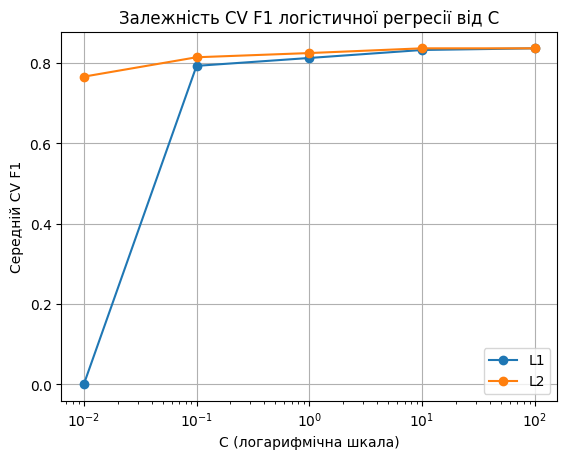

In [117]:
import matplotlib.pyplot as plt

df_l1=df[df["param_classifier__penalty"] == "l1"]
df_l2=df[df["param_classifier__penalty"] == "l2"]
plt.plot(df_l1["param_classifier__C"], df_l1["mean_test_score"], marker="o", label="L1")
plt.plot(df_l2["param_classifier__C"], df_l2["mean_test_score"], marker="o", label="L2")
plt.xscale("log")
plt.xlabel("C (логарифмічна шкала)")
plt.ylabel("Середній CV F1")
plt.title("Залежність CV F1 логістичної регресії від C")
plt.legend()
plt.grid(True)
plt.show()

### Вплив C та типу регуляризації на CV F1

- **Мале C (сильна регуляризація) шкодить.** При C = 0,01 CV F1 для L2 лише 0,7658, а для L1 дорівнює 0: штраф настільки сильний, що модель не передбачає позитивний клас.
- **Зі зростанням C якість зростає й виходить на плато.** Для L2 CV F1 піднімається від 0,7658 (C = 0,01) до 0,8141, 0,8245, 0,8363 (C = 10) і лишається 0,8363 при C = 100. Для L1 те саме: 0,7926, 0,8123, 0,8321, 0,8363 (C = 100).
- **L2 стабільніший при малих C**, L1 при C від 10 майже не відрізняється від L2.
- Три конфігурації (L2 з C = 10, L2 з C = 100, L1 з C = 100) мають однаковий CV F1 = 0,8363. За правилом «за однакового F1 беремо сильнішу регуляризацію» обрано **L2, C = 10**.

In [118]:
best_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(penalty="l2", C=10, solver="liblinear", max_iter=2000))
])
best_lr.fit(X_train, y_train)
coef_df=pd.DataFrame({"feature": best_lr.named_steps["preprocessor"].get_feature_names_out(), "coef": best_lr.named_steps["classifier"].coef_[0]})
coef_df["abs_coef"]=np.abs(coef_df["coef"])

print("П'ять найбільших за модулем коефіцієнтів (L2, C=10):")
display(coef_df.sort_values("abs_coef", ascending=False).head(5).round(4))

П'ять найбільших за модулем коефіцієнтів (L2, C=10):


,feature,coef,abs_coef
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


### Найбільші за модулем коефіцієнти (L2, C = 10)

| Ознака | Коефіцієнт | Вплив на log-odds класу 1 |
|---|---:|---|
| ca = 0 | -1,9262 | знижує |
| cp = 4 | 1,1886 | підвищує |
| thal = 7 | 0,9779 | підвищує |
| cp = 1 | -0,8921 | знижує |
| sex = 0 | -0,8802 | знижує |

Додатний коефіцієнт збільшує log-odds позитивного класу (наявність ознак захворювання) за інших рівних умов, від'ємний зменшує. Усі п'ять найбільших коефіцієнтів належать категоріальним ознакам, закодованим one-hot (кожен така колонка дорівнює 0 або 1), жодна числова ознака в п'ятірку не потрапила. Тому ці величини не можна напряму порівнювати з коефіцієнтами числових ознак: для числових (після StandardScaler) коефіцієнт показує зміну log-odds на одне стандартне відхилення ознаки, а для one-hot на перехід від 0 до 1. Найсильніше на результат впливає `ca = 0` (відсутність помітних судин знижує оцінку ризику), далі `cp = 4` і `thal = 7`. Коефіцієнти описують зв'язок у даних, а не причинно-наслідковий чи медичний вплив: наприклад, від'ємний коефіцієнт у `cp = 1` не означає, що типова стенокардія захищає від хвороби.

### Висновок за практичною роботою 4

- **Масштабування.** CV F1 (0,8245) і CV Recall (0,7834) зі StandardScaler і без нього збіглися, CV ROC AUC трохи вищий зі стандартизацією (0,9025 проти 0,8997), розкид між фолдами теж трохи менший (0,0144 проти 0,0157). Головна різниця в збіжності: зі стандартизацією оптимізатору вистачило 18 ітерацій, без неї знадобилося 1238. Попереджень про збіжність не було в обох випадках. Для подальшої роботи обрано варіант зі StandardScaler.
- **Регуляризація.** Для C = 0,01 CV F1 найнижчий: 0,7658 для L2 і 0 для L1 (штраф настільки сильний, що модель перестала передбачати позитивний клас). L2 стабільніший за L1 при малих C, а при C від 10 обидва штрафи дають майже однаковий результат.
- **Значення C.** З ростом C якість зростає й виходить на плато: для L2 від 0,7658 (C = 0,01) до 0,8363 (C = 10), далі без змін. Три конфігурації (L2 з C = 10, L2 з C = 100, L1 з C = 100) мали однаковий CV F1 = 0,8363. Обрано L2 з C = 10 за правилом «за однакового F1 беремо сильнішу регуляризацію», CV F1 = 0,8363, std = 0,0127.
- **Коефіцієнти.** Найбільший вплив мають `ca = 0` (−1,9262), `cp = 4` (1,1886) і `thal = 7` (0,9779). Це зв'язок у даних, а не доказ причинності.
- Тестову вибірку на цьому етапі не використовували.

## Додаткове завдання: детальний аналіз коефіцієнтів логістичної регресії

Для обраної за крос-валідацією моделі (L2, C = 10, зі StandardScaler) розглянуто всі 28 коефіцієнтів, а не лише п'ять найбільших. Коефіцієнти відсортовано за модулем і показано на стовпчастому графіку: додатні значення підвищують log-odds позитивного класу (наявність ознак захворювання), від'ємні знижують. Числові ознаки стандартизовано, тому їхні коефіцієнти показують зміну log-odds на одне стандартне відхилення, а коефіцієнти one-hot-ознак показують перехід категорії від 0 до 1. Аналіз описує зв'язок у навчальних даних і не доводить причинно-наслідкового чи медичного впливу.

In [119]:
coef_sorted= coef_df.sort_values("abs_coef", ascending=False).round(4)
print("Усі 28 коефіцієнтів, відсортовані за модулем:")
print(coef_sorted)

Усі 28 коефіцієнтів, відсортовані за модулем:
             feature    coef  abs_coef
21       cat__ca_0.0 -1.9262    1.9262
10       cat__cp_4.0  1.1886    1.1886
27     cat__thal_7.0  0.9779    0.9779
7        cat__cp_1.0 -0.8921    0.8921
5       cat__sex_0.0 -0.8802    0.8802
23       cat__ca_2.0  0.8409    0.8409
6       cat__sex_1.0  0.8337    0.8337
24       cat__ca_3.0  0.8003    0.8003
19    cat__slope_2.0  0.7799    0.7799
9        cat__cp_3.0 -0.6662    0.6662
18    cat__slope_1.0 -0.5885    0.5885
26     cat__thal_6.0 -0.5359    0.5359
25     cat__thal_3.0 -0.4883    0.4883
1      num__trestbps  0.4302    0.4302
3       num__thalach -0.3921    0.3921
15  cat__restecg_2.0  0.3320    0.3320
14  cat__restecg_1.0 -0.3313    0.3313
8        cat__cp_2.0  0.3233    0.3233
16    cat__exang_0.0 -0.2918    0.2918
4       num__oldpeak  0.2457    0.2457
17    cat__exang_1.0  0.2454    0.2454
22       cat__ca_1.0  0.2385    0.2385
20    cat__slope_3.0 -0.2378    0.2378
2          num__ch

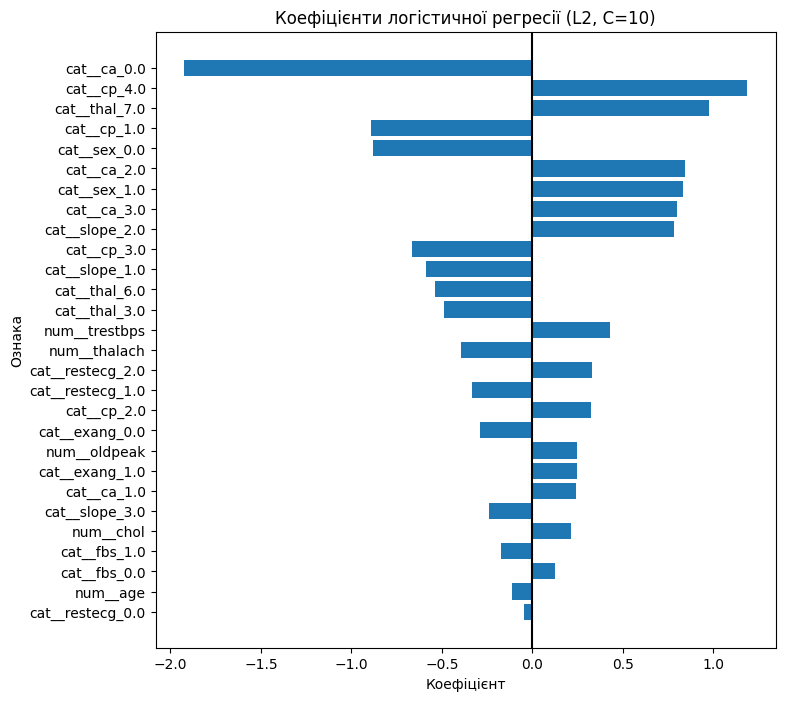

In [120]:
plt.figure(figsize=(8, 8))
coef_rev = coef_sorted.iloc[::-1]
plt.barh(coef_rev["feature"], coef_rev["coef"])
plt.axvline(0, color="black")
plt.xlabel("Коефіцієнт")
plt.ylabel("Ознака")
plt.title("Коефіцієнти логістичної регресії (L2, C=10)")
plt.show()

### Висновки з аналізу коефіцієнтів

**Загальна картина.** Із 28 коефіцієнтів найбільші за модулем належать категоріальним ознакам: перші 13 позицій займають one-hot-колонки, а перша числова ознака (`trestbps`, 0,4302) лише 14-та. Найслабші коефіцієнти мають `restecg = 0` (-0,0472) та `age` (-0,1122).

**Групи категоріальних ознак.**
- `ca` (кількість судин): `ca = 0` має найсильніший вплив у моделі (-1,9262), тобто відсутність помітних судин різко знижує оцінку ризику. Для `ca = 1, 2, 3` коефіцієнти додатні (0,2385; 0,8409; 0,8003), тобто більша кількість судин підвищує ризик.
- `cp` (тип болю в грудях): `cp = 4` підвищує ризик (1,1886), `cp = 2` трохи підвищує (0,3233), а `cp = 1` і `cp = 3` знижують (-0,8921 і -0,6662).
- `thal`: `thal = 7` підвищує ризик (0,9779), тоді як `thal = 3` і `thal = 6` знижують (-0,4883 і -0,5359).
- `slope`: `slope = 2` підвищує (0,7799), `slope = 1` і `slope = 3` знижують (-0,5885 і -0,2378).
- `restecg`: `restecg = 2` підвищує (0,3320), `restecg = 1` знижує (-0,3313), `restecg = 0` майже нейтральний (-0,0472).

**Бінарні ознаки.** Для `sex`, `exang` і `fbs` модель має по два коефіцієнти (для 0 та для 1), які майже дзеркальні (наприклад, `sex = 0` це -0,8802, а `sex = 1` це 0,8337). Реальний вплив такої ознаки показує різниця між ними: перехід від `sex = 0` до `sex = 1` змінює log-odds приблизно на 1,71, для `exang` на 0,54, для `fbs` на -0,30. Тому окремі коефіцієнти таких колонок не слід читати поодинці.

**Числові ознаки** (стандартизовані, тому порівнянні між собою): `trestbps` (0,4302) і `thalach` (-0,3921) впливають найбільше, далі `oldpeak` (0,2457), `chol` (0,2118) та `age` (-0,1122). Від'ємний знак у `age` не означає, що вік знижує ризик: коефіцієнт показує вплив за незмінних інших ознак (насамперед `thalach`), і він малий.

**Обмеження.** Коефіцієнти описують зв'язок у навчальних даних і не доводять причинно-наслідкового чи медичного впливу.

In [121]:
# Крок 14.1 (методичка): k-NN без масштабування і зі StandardScaler
from sklearn.neighbors import KNeighborsClassifier
numeric_pipeline_noscale = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_noscale = ColumnTransformer([
    ("num", numeric_pipeline_noscale, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

knn_noscale = Pipeline([
    ("preprocessor", preprocessor_noscale),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_scaled = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

res_knn_scaled = cross_validate(knn_scaled, X_train, y_train, cv=cv, scoring=scoring)
res_knn_noscale = cross_validate(knn_noscale, X_train, y_train, cv=cv, scoring=scoring)

rows_knn = []
for name, res in [("Зі StandardScaler", res_knn_scaled), ("Без масштабування", res_knn_noscale)]:
    print("k-NN (k=5):", name)
    print("CV F1, середнє:", round(res["test_F1"].mean(), 4))
    print("CV F1, std:", round(res["test_F1"].std(), 4))
    print("CV ROC AUC, середнє:", round(res["test_ROC_AUC"].mean(), 4))
    print("CV ROC AUC, std:", round(res["test_ROC_AUC"].std(), 4))
    print("CV Recall, середнє:", round(res["test_RECALL"].mean(), 4))
    rows_knn.append({"Pipeline": name, "CV F1": res["test_F1"].mean(), "F1 std": res["test_F1"].std(), "ROC AUC середнє": res["test_ROC_AUC"].mean(), "ROC AUC std": res["test_ROC_AUC"].std(), "Recall середнє": res["test_RECALL"].mean()})

knn_scale_table = pd.DataFrame(rows_knn)
display(knn_scale_table.round(4))

k-NN (k=5): Зі StandardScaler
CV F1, середнє: 0.7989
CV F1, std: 0.0426
CV ROC AUC, середнє: 0.8712
CV ROC AUC, std: 0.0387
CV Recall, середнє: 0.7826
k-NN (k=5): Без масштабування
CV F1, середнє: 0.512
CV F1, std: 0.0134
CV ROC AUC, середнє: 0.6419
CV ROC AUC, std: 0.0319
CV Recall, середнє: 0.4866


,Pipeline,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,Зі StandardScaler,0.7989,0.0426,0.8712,0.0387,0.7826
1,Без масштабування,0.5120,0.0134,0.6419,0.0319,0.4866


### Крок 14.1 (методичка): k-NN без масштабування і зі StandardScaler

Порівняння виконано лише за крос-валідацією на train, k=5 для обох варіантів.

| Варіант | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---|---:|---:|---:|---:|
| Зі StandardScaler | 0,7989 | 0,0426 | 0,8712 | 0,7826 |
| Без масштабування | 0,5120 | 0,0134 | 0,6419 | 0,4866 |

Масштабування сильно вплинуло на k-NN. Без нього CV F1 впав з 0,7989 до 0,5120 (різниця приблизно 0,29), ROC AUC з 0,8712 до 0,6419, Recall з 0,7826 до 0,4866, тобто модель пропускає більше половини пацієнтів із ознаками захворювання. ROC AUC 0,6419 лише трохи вищий за 0,5, тобто за випадкове вгадування.

Причина в тому, що k-NN обчислює відстань по всіх ознаках разом. Без масштабування chol, trestbps і thalach мають діапазон у десятки та сотні одиниць, oldpeak лише в одиниці, а one-hot колонки тільки 0 або 1. Тому відстань майже повністю визначається ознаками з великим числовим діапазоном, а sex, cp, ca і thal майже не впливають на вибір сусідів. StandardScaler приводить числові ознаки до однакового масштабу, і всі вони вносять порівнянний внесок. Менше std у варіанті без масштабування (0,0134 проти 0,0426) означає стабільність на низькому рівні, а не перевагу.

Для порівняння, логістична регресія майже не залежала від масштабу (CV F1 0,8245 в обох варіантах), бо її коефіцієнти підлаштовуються під масштаб ознак, а k-NN такої можливості не має. Для подальших кроків використовуємо k-NN зі StandardScaler.

k-NN зі StandardScaler: CV за різними k


,k,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,3,0.8042,0.0272,0.8709,0.0406,0.8008
1,5,0.7989,0.0426,0.8712,0.0387,0.7826
2,7,0.7942,0.0184,0.8721,0.0306,0.7656
3,9,0.7872,0.0294,0.8744,0.0210,0.7557
4,11,0.7791,0.0273,0.8806,0.0252,0.7375
5,15,0.7651,0.0246,0.8729,0.0202,0.7209


Найбільший середній CV F1: 0.8042
Найкраще k: 3


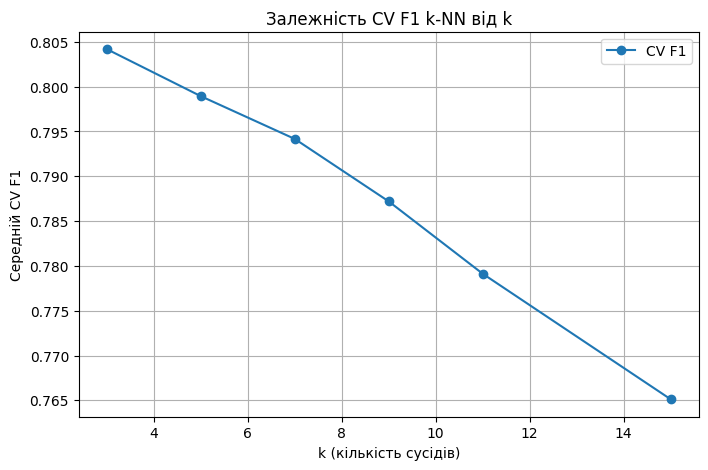

In [122]:
# Крок 14.2 (методичка): вибір кількості сусідів k

k = [3, 5, 7, 9, 11, 15]
res_rows = []

for k_n in k:
    knn_scaled_k = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k_n))
    ])
    crv_knn_scaled = cross_validate(knn_scaled_k, X_train, y_train, cv=cv, scoring=scoring)
    res_rows.append({
        "k": k_n,
        "CV F1": crv_knn_scaled["test_F1"].mean(),
        "F1 std": crv_knn_scaled["test_F1"].std(),
        "ROC AUC середнє": crv_knn_scaled["test_ROC_AUC"].mean(),
        "ROC AUC std": crv_knn_scaled["test_ROC_AUC"].std(),
        "Recall середнє": crv_knn_scaled["test_RECALL"].mean()
    })

df_knn_k = pd.DataFrame(res_rows)

# Пошук найкращого k: найбільший середній CV F1,
# при однаковому F1 беремо більше k (гладша й простіша модель)
max_CV_F1 = -100
k_max = -100
for elm in res_rows:
    if elm["CV F1"] >= max_CV_F1:
        max_CV_F1 = elm["CV F1"]
        k_max = elm["k"]

print("k-NN зі StandardScaler: CV за різними k")
display(df_knn_k.round(4))
print("Найбільший середній CV F1:", round(max_CV_F1, 4))
print("Найкраще k:", k_max)

# Графік залежності CV F1 від k
plt.figure(figsize=(8, 5))
plt.plot(df_knn_k["k"], df_knn_k["CV F1"], marker="o", label="CV F1")
plt.xlabel("k (кількість сусідів)")
plt.ylabel("Середній CV F1")
plt.title("Залежність CV F1 k-NN від k")
plt.legend()
plt.grid(True)
plt.show()

### Крок 14.2 (методичка): вибір кількості сусідів k

k-NN зі StandardScaler, k = 3, 5, 7, 9, 11, 15, порівняння лише за CV на train.

| k | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---:|---:|---:|---:|---:|
| 3 | 0,8042 | 0,0272 | 0,8709 | 0,8008 |
| 5 | 0,7989 | 0,0426 | 0,8712 | 0,7826 |
| 7 | 0,7942 | 0,0184 | 0,8721 | 0,7656 |
| 9 | 0,7872 | 0,0294 | 0,8744 | 0,7557 |
| 11 | 0,7791 | 0,0273 | 0,8806 | 0,7375 |
| 15 | 0,7651 | 0,0246 | 0,8729 | 0,7209 |

Найбільший середній CV F1 дало k=3 (0,8042), його обрано за правилом найбільшого CV F1. CV F1 монотонно зменшується зі зростанням k: з 0,8042 до 0,7651 при k=15. Recall падає ще помітніше, з 0,8008 до 0,7209, тоді як ROC AUC майже не змінюється (приблизно 0,87). Це означає, що здатність ранжувати об'єкти лишається схожою, але при великому k модель частіше голосує за більший клас 0 і пропускає більше пацієнтів із ознаками захворювання. Дуже великі k згладжують локальну структуру, тому якість падає. Різниця між сусідніми k (приблизно 0,005) менша за std між фолдами (від 0,0184 до 0,0426), тому k=3, 5 і 7 за якістю близькі. Значення k=1 і 2 не перевірялися.

In [123]:
# Крок 14.3 (методичка): евклідова та мангеттенська відстані, k = k_max
res_rows_kmax = []
for dist in ["euclidean", "manhattan"]:
    knn_scaled_kmax = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k_max, metric=dist))
    ])
    crv_knn_scaled_kmax = cross_validate(knn_scaled_kmax, X_train, y_train, cv=cv, scoring=scoring)
    res_rows_kmax.append({
        "name_metric": dist,
        "CV F1": crv_knn_scaled_kmax["test_F1"].mean(),
        "F1 std": crv_knn_scaled_kmax["test_F1"].std(),
        "ROC AUC середнє": crv_knn_scaled_kmax["test_ROC_AUC"].mean(),
        "ROC AUC std": crv_knn_scaled_kmax["test_ROC_AUC"].std(),
        "Recall середнє": crv_knn_scaled_kmax["test_RECALL"].mean()
    })

df_knn_kmax = pd.DataFrame(res_rows_kmax)
print("k-NN, k =", k_max, ": порівняння мір відстані (CV)")
display(df_knn_kmax.round(4))

k-NN, k = 3 : порівняння мір відстані (CV)


,name_metric,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,euclidean,0.8042,0.0272,0.8709,0.0406,0.8008
1,manhattan,0.8175,0.0304,0.8768,0.0333,0.7917


### Крок 14.3 (методичка): міри відстані

k-NN зі StandardScaler, k=3 (найкраще за кроком 14.2), порівняння лише за CV на train.

| Міра відстані | CV F1 | CV F1 std | CV ROC AUC | CV Recall |
|---|---:|---:|---:|---:|
| Евклідова | 0,8042 | 0,0272 | 0,8709 | 0,8008 |
| Мангеттенська | 0,8175 | 0,0304 | 0,8768 | 0,7917 |

Мангеттенська відстань дала вищий CV F1 (0,8175 проти 0,8042, різниця 0,0133) і вищий CV ROC AUC (0,8768 проти 0,8709). Recall трохи кращий у евклідової (0,8008 проти 0,7917). Різниця F1 менша за std між фолдами (0,0272 і 0,0304), тому перевага невелика. Основна метрика F1, тож найкращою k-NN обрано k=3 з мангеттенською відстанню (CV F1 0,8175). Обмеження: k обирали за евклідової відстані, а міри порівняли лише для цього k.

In [124]:
# Крок 15 (методичка): GaussianNB, LDA і QDA, порівняння за CV

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

probabilistic_models = [
    {"name": "GaussianNB", "model": GaussianNB()},
    {"name": "LinearDiscriminantAnalysis", "model": LinearDiscriminantAnalysis()},
    {"name": "QuadraticDiscriminantAnalysis", "model": QuadraticDiscriminantAnalysis()}
]

res_rows_probabilistic_model = []
for class_model in probabilistic_models:
    print("Модель:", class_model["name"])
    probabilistic_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", class_model["model"])
    ])
    crv_probabilistic_model = cross_validate(probabilistic_model, X_train, y_train, cv=cv, scoring=scoring)
    res_rows_probabilistic_model.append({
        "name": class_model["name"],
        "CV F1": crv_probabilistic_model["test_F1"].mean(),
        "F1 std": crv_probabilistic_model["test_F1"].std(),
        "ROC AUC середнє": crv_probabilistic_model["test_ROC_AUC"].mean(),
        "ROC AUC std": crv_probabilistic_model["test_ROC_AUC"].std(),
        "Recall середнє": crv_probabilistic_model["test_RECALL"].mean()
    })

df_probabilistic_model = pd.DataFrame(res_rows_probabilistic_model)
print("GaussianNB, LDA, QDA: порівняння за CV")
display(df_probabilistic_model.round(4))

Модель: GaussianNB
Модель: LinearDiscriminantAnalysis
Модель: QuadraticDiscriminantAnalysis


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

GaussianNB, LDA, QDA: порівняння за CV


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


,name,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,GaussianNB,0.7495,0.0215,0.8773,0.0214,0.8458
1,LinearDiscriminantAnalysis,0.8128,0.0257,0.8993,0.0156,0.7656
2,QuadraticDiscriminantAnalysis,0.5709,0.1433,0.7607,0.0411,0.8186


In [125]:
# Крок 15.3 (методичка): стабільність QDA, перевірка reg_param

res_rows_QDA_model = []
for reg_param in [0, 0.01, 0.1]:
    print("QDA, reg_param =", reg_param)
    QDA_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", QuadraticDiscriminantAnalysis(reg_param=reg_param))
    ])
    crv_QDA_model = cross_validate(QDA_model, X_train, y_train, cv=cv, scoring=scoring)
    res_rows_QDA_model.append({
        "reg_param": reg_param,
        "CV F1": crv_QDA_model["test_F1"].mean(),
        "F1 std": crv_QDA_model["test_F1"].std(),
        "ROC AUC середнє": crv_QDA_model["test_ROC_AUC"].mean(),
        "ROC AUC std": crv_QDA_model["test_ROC_AUC"].std(),
        "Recall середнє": crv_QDA_model["test_RECALL"].mean()
    })

df_QDA_model = pd.DataFrame(res_rows_QDA_model)
print("QDA: порівняння reg_param (CV)")
display(df_QDA_model.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

QDA, reg_param = 0


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


QDA, reg_param = 0.01
QDA, reg_param = 0.1
QDA: порівняння reg_param (CV)


,reg_param,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,0.00,0.5709,0.1433,0.7607,0.0411,0.8186
1,0.01,0.7709,0.0440,0.8343,0.0414,0.7743
2,0.10,0.7962,0.0271,0.8680,0.0337,0.7743


### Кроки 15.1–15.3 (методичка): GaussianNB, LDA, QDA

Усі три моделі в окремих Pipeline з тим самим препроцесором (зі StandardScaler), порівняння лише за CV на train.

| Модель | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---|---:|---:|---:|---:|
| GaussianNB | 0,7495 | 0,0215 | 0,8773 | 0,8458 |
| LDA | 0,8128 | 0,0257 | 0,8993 | 0,7656 |
| QDA (reg_param=0) | 0,5709 | 0,1433 | 0,7607 | 0,8186 |

Найкраща за CV F1 і CV ROC AUC серед цих трьох моделей LDA (0,8128 і 0,8993). GaussianNB має найвищий Recall (0,8458), але нижчий F1.

**Стабільність QDA.** При reg_param=0 QDA нестабільна: F1 лише 0,5709, std між фолдами 0,1433 (в інших моделей приблизно 0,02), і під час навчання виникають попередження LinAlgWarning про коваріаційну матрицю неповного рангу. Після one-hot-кодування колонки однієї категоріальної ознаки в сумі дають 1, а в окремому класі й фолді певна категорія може не зустрітись узагалі, тому матриця виродженa. Попередження не приховано.

| reg_param | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---:|---:|---:|---:|---:|
| 0 | 0,5709 | 0,1433 | 0,7607 | 0,8186 |
| 0,01 | 0,7709 | 0,0440 | 0,8343 | 0,7743 |
| 0,1 | 0,7962 | 0,0271 | 0,8680 | 0,7743 |

Регуляризація допомогла: при reg_param=0,1 F1 зріс до 0,7962, std впав до 0,0271, попередження зникли. Значення 0,1 найкраще серед перевірених, але лежить на краю сітки, а більші значення не перевірялись. Для подальшого порівняння використовується QDA з reg_param=0,1. Найкраща ймовірнісна модель за CV F1 це LDA (0,8128).

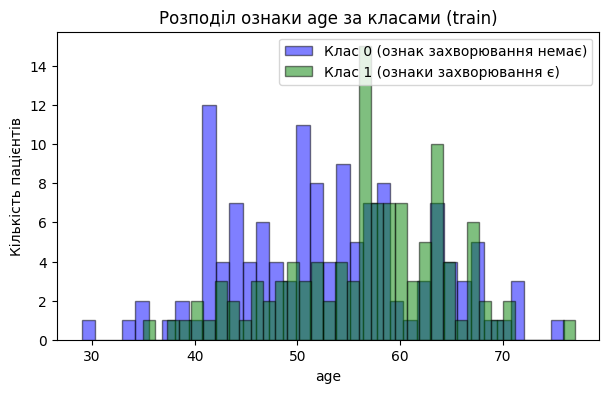

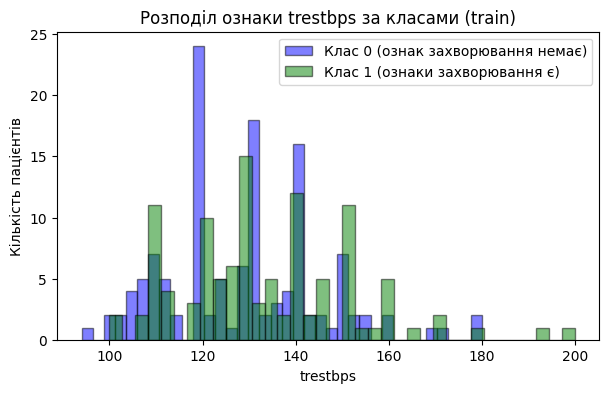

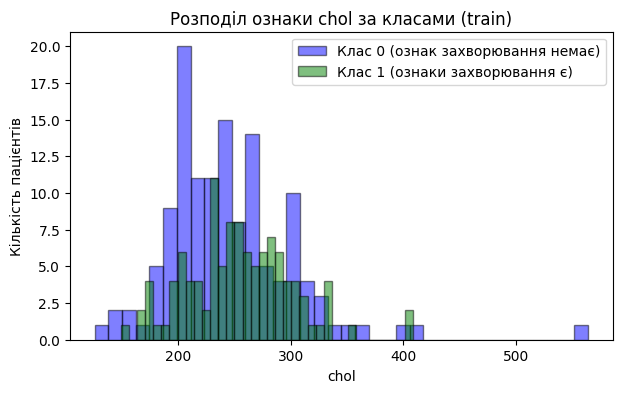

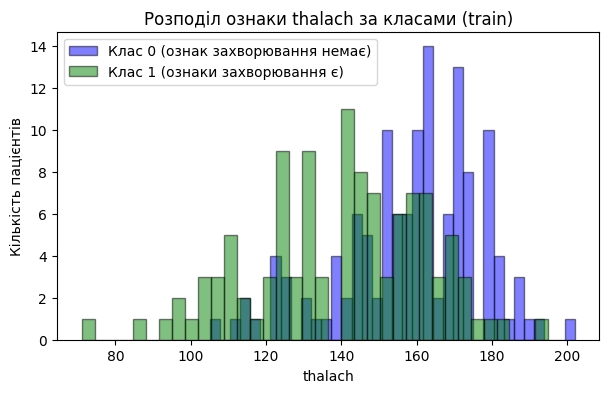

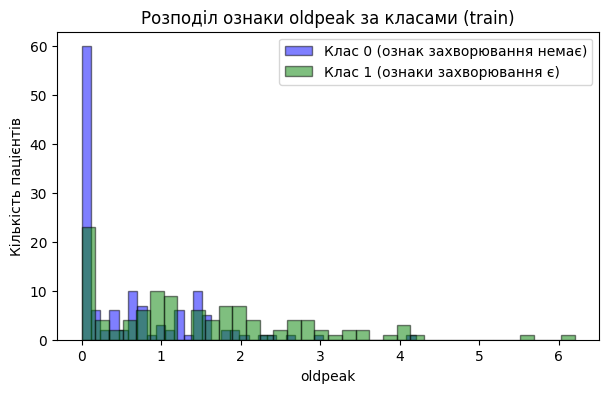

In [126]:
# Крок 6 (методичка): гістограми числових ознак за класами (для GaussianNB)

for numeric_character in numeric_columns:
    plt.figure(figsize=(7, 4))
    plt.hist(X_train[y_train == 0][numeric_character], color='blue', edgecolor='black',
             bins=int(180/5), alpha=0.5, label="Клас 0 (ознак захворювання немає)")
    plt.hist(X_train[y_train == 1][numeric_character], color='green', edgecolor='black',
             bins=int(180/5), alpha=0.5, label="Клас 1 (ознаки захворювання є)")
    plt.xlabel(numeric_character)
    plt.ylabel("Кількість пацієнтів")
    plt.title("Розподіл ознаки " + numeric_character + " за класами (train)")
    plt.legend()
    plt.show()

### Крок 6 (методичка): описовий аналіз розподілів для GaussianNB

Побудовано гістограми числових ознак age, trestbps, oldpeak, chol і thalach окремо для кожного класу (лише train, тестова вибірка не використовувалась). Це описовий аналіз, а не підстава для зміни моделі.

Найкраще класи розрізняє thalach: у класу 1 значення зсунуті вліво (основна маса приблизно 100–150), у класу 0 приблизно 140–180, перекриття середнє. Клас 1 також старший за віком (основна маса приблизно 55–68), але перекриття за age велике. Ознаки chol і trestbps у двох класів майже збігаються, тому вони слабко розрізняють класи.

Припущення GaussianNB про нормальний розподіл у межах класу виконується приблизно для thalach, chol і trestbps. Для oldpeak воно порушується: приблизно 60 пацієнтів класу 0 мають значення близько 0, розподіл сильно скошений вправо, дзвона немає. Для age у класу 0 розподіл теж має кілька піків. Крім того, після one-hot-кодування в моделі є бінарні колонки (0 або 1), для яких нормальний розподіл не підходить, і колонки однієї категорії не є незалежними, що порушує припущення про умовну незалежність ознак. Це узгоджується з нижчим CV F1 у GaussianNB (0,7495) порівняно з LDA (0,8128), але причинний зв'язок не перевірявся.

In [127]:
# Крок 8 (методичка): позавибіркові (OOF) ймовірності класу 1

from sklearn.model_selection import cross_val_predict

probabilistic_models_oof = [
    {"name": "GaussianNB", "model": GaussianNB()},
    {"name": "LinearDiscriminantAnalysis", "model": LinearDiscriminantAnalysis()},
    {"name": "QuadraticDiscriminantAnalysis", "model": QuadraticDiscriminantAnalysis(reg_param=0.1)}
]

df_probabilistic_model_oof = pd.DataFrame(y_train)
for class_model in probabilistic_models_oof:
    print("Модель:", class_model["name"])
    probabilistic_models_off = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", class_model["model"])
    ])
    crv_probabilistic_model_oof = cross_val_predict(probabilistic_models_off, X_train, y_train, cv=cv, method="predict_proba")
    df_probabilistic_model_oof[class_model["name"]] = crv_probabilistic_model_oof[:, 1]

print("OOF-ймовірності класу 1 для перших 8 об'єктів train")
display(df_probabilistic_model_oof.round(4).head(8))

Модель: GaussianNB
Модель: LinearDiscriminantAnalysis
Модель: QuadraticDiscriminantAnalysis
OOF-ймовірності класу 1 для перших 8 об'єктів train


,target,GaussianNB,LinearDiscriminantAnalysis,QuadraticDiscriminantAnalysis
180,1,1.0000,0.9039,0.6115
208,0,0.0000,0.0220,0.0075
167,0,0.0000,0.4726,0.2175
105,0,0.4342,0.1608,0.0369
297,1,1.0000,0.6167,0.6750
120,1,1.0000,0.9787,0.9980
55,1,1.0000,0.9981,0.9999
123,1,1.0000,0.9498,1.0000


### Крок 8 (методичка): позавибіркові (OOF) ймовірності для train-об'єктів

За допомогою cross_val_predict(method="predict_proba") з тією самою StratifiedKFold для кожного об'єкта train отримано ймовірність класу 1 від моделі, яка не навчалась на цьому об'єкті. Нижче показано перші 8 об'єктів (QDA з reg_param=0,1).

GaussianNB дає найекстремальніші ймовірності: у 7 із 8 показаних об'єктів значення дорівнює 1,0000 або 0,0000. LDA дає помірніші значення (від 0,0220 до 0,9787), QDA посередині. Ймовірно, це пов'язано з припущенням GaussianNB про незалежність ознак: колонки one-hot однієї категорії залежні, і їхні внески враховуються кілька разів, але це припущення не перевірялось. Для всіх 8 показаних об'єктів прогноз при порозі 0,5 правильний, але вибірка малa і не дозволяє робити висновок про якість моделей.

### Крок 9 (методичка): найкращі k-NN і ймовірнісна модель за CV

| Модель | Параметри | CV F1 | CV F1 std | CV ROC AUC | CV Recall |
|---|---|---:|---:|---:|---:|
| k-NN (найкраща) | k=3, мангеттенська відстань, StandardScaler | 0,8175 | 0,0304 | 0,8768 | 0,7917 |
| LDA (найкраща ймовірнісна) | за замовчуванням | 0,8128 | 0,0257 | 0,8993 | 0,7656 |
| QDA | reg_param=0,1 | 0,7962 | 0,0271 | 0,8680 | 0,7743 |
| GaussianNB | за замовчуванням | 0,7495 | 0,0215 | 0,8773 | 0,8458 |

Найкраща k-NN: k=3 з мангеттенською відстанню (CV F1 0,8175). Найкраща ймовірнісна модель: LDA (CV F1 0,8128, CV ROC AUC 0,8993). За F1 вони майже однакові (різниця 0,0047, менша за std між фолдами), а за ROC AUC LDA вища на 0,0225. Для ПР7 до порівняння беремо обидві.

### Крок 10 (методичка): висновок ПР5

**Масштаб.** k-NN сильно залежить від масштабу: при k=5 без масштабування CV F1 лише 0,5120, зі StandardScaler 0,7989, бо відстань визначали ознаки з великим діапазоном (chol, trestbps, thalach). Тому для k-NN обрано StandardScaler.

**Кількість сусідів.** CV F1 зменшувався зі зростанням k: з 0,8042 при k=3 до 0,7651 при k=15, тому обрано k=3. Recall при цьому теж падав (з 0,8008 до 0,7209). Значення k=1 і 2 не перевірялись.

**Міра відстані.** Для k=3 мангеттенська відстань дала CV F1 0,8175 проти 0,8042 в евклідової. Різниця (0,0133) менша за std між фолдами, тому перевага невелика.

**Ймовірнісні моделі.** Найкраща LDA (CV F1 0,8128, ROC AUC 0,8993). GaussianNB має F1 0,7495, але найвищий Recall (0,8458): припущення про нормальний розподіл порушується для oldpeak, а one-hot колонки залежні, що суперечить припущенню про незалежність. QDA при reg_param=0 нестабільна (F1 0,5709, std 0,1433, LinAlgWarning), а при reg_param=0,1 стабілізувалась (F1 0,7962, std 0,0271, попереджень немає). Позавибіркові ймовірності показали, що GaussianNB найбільш самовпевнений: у 7 із 8 показаних об'єктів значення 0,0000 або 1,0000.

Тестова вибірка у ПР5 не використовувалась.

QDA, reg_param = 0


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

QDA, reg_param = 0.001
QDA, reg_param = 0.01
QDA, reg_param = 0.05
QDA, reg_param = 0.1
QDA, reg_param = 0.2
QDA, reg_param = 0.3
QDA, reg_param = 0.5
QDA, reg_param = 0.7
QDA, reg_param = 1
QDA: розширена сітка reg_param (CV)


,reg_param,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,0.000,0.5709,0.1433,0.7607,0.0411,0.8186
1,0.001,0.7543,0.0509,0.8274,0.0469,0.7739
2,0.010,0.7709,0.0440,0.8343,0.0414,0.7743
3,0.050,0.7837,0.0343,0.8612,0.0306,0.7834
4,0.100,0.7962,0.0271,0.8680,0.0337,0.7743
5,0.200,0.7957,0.0274,0.8771,0.0274,0.7561
6,0.300,0.7921,0.0322,0.8822,0.0236,0.7561
7,0.500,0.7988,0.0286,0.8883,0.0300,0.7561
8,0.700,0.8022,0.0451,0.8844,0.0395,0.7561
9,1.000,0.7717,0.0447,0.8718,0.0360,0.7383


Найбільший середній CV F1: 0.8022
Найкраще reg_param: 0.7


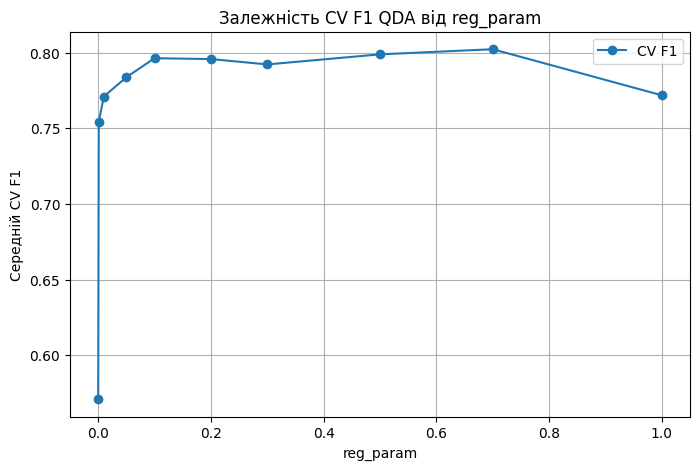

In [128]:
# Додаткове ПР5, частина 1: розширена сітка reg_param для QDA

reg_param_grid = [0, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1]

res_rows_QDA_model_ext = []
for reg_param in reg_param_grid:
    print("QDA, reg_param =", reg_param)
    QDA_model_ext = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", QuadraticDiscriminantAnalysis(reg_param=reg_param))
    ])
    crv_QDA_model_ext = cross_validate(QDA_model_ext, X_train, y_train, cv=cv, scoring=scoring)
    res_rows_QDA_model_ext.append({
        "reg_param": reg_param,
        "CV F1": crv_QDA_model_ext["test_F1"].mean(),
        "F1 std": crv_QDA_model_ext["test_F1"].std(),
        "ROC AUC середнє": crv_QDA_model_ext["test_ROC_AUC"].mean(),
        "ROC AUC std": crv_QDA_model_ext["test_ROC_AUC"].std(),
        "Recall середнє": crv_QDA_model_ext["test_RECALL"].mean()
    })

df_QDA_model_ext = pd.DataFrame(res_rows_QDA_model_ext)
print("QDA: розширена сітка reg_param (CV)")
display(df_QDA_model_ext.round(4))

# Пошук найкращого reg_param: найбільший середній CV F1,
# при однаковому F1 беремо більше значення (список іде за зростанням)
max_CV_F1_QDA_ext = -100
for elm in res_rows_QDA_model_ext:
    if elm["CV F1"] >= max_CV_F1_QDA_ext:
        max_CV_F1_QDA_ext = elm["CV F1"]
        reg_param_max = elm["reg_param"]

print("Найбільший середній CV F1:", round(max_CV_F1_QDA_ext, 4))
print("Найкраще reg_param:", reg_param_max)

# Графік залежності CV F1 від reg_param
plt.figure(figsize=(8, 5))
plt.plot(df_QDA_model_ext["reg_param"], df_QDA_model_ext["CV F1"], marker="o", label="CV F1")
plt.xlabel("reg_param")
plt.ylabel("Середній CV F1")
plt.title("Залежність CV F1 QDA від reg_param")
plt.legend()
plt.grid(True)
plt.show()

### Додаткове завдання ПР5, частина 1: розширена сітка reg_param для QDA

Перевірено reg_param = 0; 0,001; 0,01; 0,05; 0,1; 0,2; 0,3; 0,5; 0,7; 1 за тією самою StratifiedKFold, лише на train.

| reg_param | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---:|---:|---:|---:|---:|
| 0 | 0,5709 | 0,1433 | 0,7607 | 0,8186 |
| 0,001 | 0,7543 | 0,0509 | 0,8274 | 0,7739 |
| 0,01 | 0,7709 | 0,0440 | 0,8343 | 0,7743 |
| 0,05 | 0,7837 | 0,0343 | 0,8612 | 0,7834 |
| 0,1 | 0,7962 | 0,0271 | 0,8680 | 0,7743 |
| 0,2 | 0,7957 | 0,0274 | 0,8771 | 0,7561 |
| 0,3 | 0,7921 | 0,0322 | 0,8822 | 0,7561 |
| 0,5 | 0,7988 | 0,0286 | 0,8883 | 0,7561 |
| 0,7 | 0,8022 | 0,0451 | 0,8844 | 0,7561 |
| 1 | 0,7717 | 0,0447 | 0,8718 | 0,7383 |

Найбільший CV F1 (0,8022) дає reg_param=0,7. CV F1 різко зростає від 0 до 0,05, потім від 0,1 до 0,7 тримається на плато (0,7921–0,8022), а при reg_param=1 падає до 0,7717. Різниця між 0,1 і 0,7 (0,0060) менша за std між фолдами (0,027–0,045), тому ці значення за якістю близькі, але std при 0,7 більший (0,0451 проти 0,0271). За правилом найбільшого CV F1 для подальшого порівняння QDA беремо з reg_param=0,7 (раніше в кроці 15 на вужчій сітці було обрано 0,1).

In [129]:
# Додаткове ПР5, частина 2: склад ознак і стабільність QDA

preprocessor_num_only = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns)
])
preprocessor_num_binary = ColumnTransformer([
    ("num", numeric_pipeline, numeric_columns),
    ("cat", categorical_pipeline, ["sex", "fbs", "exang"])
])
sets = [
    {"name": "Усі ознаки", "preprocessor": preprocessor},
    {"name": "Лише числові", "preprocessor": preprocessor_num_only},
    {"name": "Числові плюс sex, fbs, exang", "preprocessor": preprocessor_num_binary}
]

reg_param_grid_feat = [0, 0.1, 0.7]
res_rows_QDA_feat = []
for feature_set in sets:
    for reg_param in reg_param_grid_feat:
        print("Набір:", feature_set["name"], ", reg_param =", reg_param)
        QDA_model_feat = Pipeline([
            ("preprocessor", feature_set["preprocessor"]),
            ("classifier", QuadraticDiscriminantAnalysis(reg_param=reg_param))
        ])
        crv_QDA_feat = cross_validate(QDA_model_feat, X_train, y_train, cv=cv, scoring=scoring)
        res_rows_QDA_feat.append({
            "Набір ознак": feature_set["name"],
            "reg_param": reg_param,
            "CV F1": crv_QDA_feat["test_F1"].mean(),
            "F1 std": crv_QDA_feat["test_F1"].std(),
            "ROC AUC середнє": crv_QDA_feat["test_ROC_AUC"].mean(),
            "ROC AUC std": crv_QDA_feat["test_ROC_AUC"].std(),
            "Recall середнє": crv_QDA_feat["test_RECALL"].mean()
        })

df_QDA_feat = pd.DataFrame(res_rows_QDA_feat)
print("QDA: склад ознак і reg_param (CV)")
display(df_QDA_feat.round(4))

Набір: Усі ознаки , reg_param = 0


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

Набір: Усі ознаки , reg_param = 0.1
Набір: Усі ознаки , reg_param = 0.7
Набір: Лише числові , reg_param = 0
Набір: Лише числові , reg_param = 0.1
Набір: Лише числові , reg_param = 0.7
Набір: Числові плюс sex, fbs, exang , reg_param = 0


/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

Набір: Числові плюс sex, fbs, exang , reg_param = 0.1
Набір: Числові плюс sex, fbs, exang , reg_param = 0.7
QDA: склад ознак і reg_param (CV)


,Набір ознак,reg_param,CV F1,F1 std,ROC AUC середнє,ROC AUC std,Recall середнє
0,Усі ознаки,0.0,0.5709,0.1433,0.7607,0.0411,0.8186
1,Усі ознаки,0.1,0.7962,0.0271,0.8680,0.0337,0.7743
2,Усі ознаки,0.7,0.8022,0.0451,0.8844,0.0395,0.7561
3,Лише числові,0.0,0.6028,0.0736,0.7569,0.0379,0.5411
4,Лише числові,0.1,0.6081,0.0640,0.7574,0.0402,0.5320
5,Лише числові,0.7,0.5979,0.0858,0.7699,0.0465,0.5498
6,"Числові плюс sex, fbs, exang",0.0,0.6140,0.1109,0.6844,0.0981,0.6968
7,"Числові плюс sex, fbs, exang",0.1,0.6569,0.0730,0.8076,0.0394,0.6040
8,"Числові плюс sex, fbs, exang",0.7,0.6904,0.0798,0.8110,0.0550,0.6399


### Додаткове завдання ПР5, частина 2: склад ознак і стабільність QDA

Порівняно QDA на трьох наборах ознак (усі 13; лише 5 числових; 5 числових плюс sex, fbs, exang) при reg_param = 0; 0,1; 0,7 за тією самою StratifiedKFold, лише на train.

| Набір ознак | reg_param | CV F1 | F1 std | CV ROC AUC | CV Recall |
|---|---:|---:|---:|---:|---:|
| Усі ознаки | 0 | 0,5709 | 0,1433 | 0,7607 | 0,8186 |
| Усі ознаки | 0,1 | 0,7962 | 0,0271 | 0,8680 | 0,7743 |
| Усі ознаки | 0,7 | 0,8022 | 0,0451 | 0,8844 | 0,7561 |
| Лише числові | 0 | 0,6028 | 0,0736 | 0,7569 | 0,5411 |
| Лише числові | 0,1 | 0,6081 | 0,0640 | 0,7574 | 0,5320 |
| Лише числові | 0,7 | 0,5979 | 0,0858 | 0,7699 | 0,5498 |
| Числові плюс sex, fbs, exang | 0 | 0,6140 | 0,1109 | 0,6844 | 0,6968 |
| Числові плюс sex, fbs, exang | 0,1 | 0,6569 | 0,0730 | 0,8076 | 0,6040 |
| Числові плюс sex, fbs, exang | 0,7 | 0,6904 | 0,0798 | 0,8110 | 0,6399 |

Без категоріальних ознак QDA працює погано: CV F1 приблизно 0,60 при будь-якому reg_param (0,6028; 0,6081; 0,5979), Recall лише 0,53–0,55. Для порівняння, з усіма ознаками й reg_param=0,7 F1 становить 0,8022, тобто на 0,2043 вище. Категоріальні ознаки (cp, ca, thal, slope, restecg та інші) несуть більшу частину інформації: додавання лише трьох бінарних піднімає F1 при reg_param=0,7 з 0,5979 до 0,6904, а решта категоріальних ще на 0,1118 до 0,8022.

Регуляризація впливає лише за наявності one-hot колонок: для всіх ознак F1 зростає з 0,5709 до 0,8022, для набору з трьома бінарними з 0,6140 до 0,6904, а для лише числових не змінюється. Це узгоджується з припущенням, що нестабільність QDA при reg_param=0 пов'язана з виродженою коваріаційною матрицею через залежні one-hot колонки, але попередження для кожного набору окремо не аналізувались. Найкращою лишається QDA з усіма ознаками й reg_param=0,7 (CV F1 0,8022, std 0,0451), її беремо до подальшого порівняння. Обмеження: перевірено лише три набори ознак.